# 27 · Does a component help the existing decision?

Omit one coordinate at a time from the existing equal-weight profile and renormalize the remaining ten weights. This is a diagnostic on the held-out set. It estimates the effect of omission in this particular combination.

Omitting open Q triplets raises same-digit retrieval from 30.3% to 33.0% in the fixed uniform profile. This is an exploratory test-panel diagnostic, with no replacement weights fitted.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage7 import METHODS, COMPONENTS, CONDITIONS, run
SOURCE=ROOT/'results'/'stage6'
OUT=ROOT/'results'/'stage7'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Preserve the original comparison
Use all eight transformed conditions and both endpoints. Keep the gallery, search policy and tie rule fixed. The two aligned magnitude controls are available in the rank audit but were never part of the uniform combination, so they are excluded here. Positive change means the omitted-coordinate variant outperformed the full uniform profile.

,endpoint,variant,top1,change,low95,high95
20,class,omit open Q triplets,0.3301,0.0270,0.0109,0.0445
16,class,omit angular m4,0.3289,0.0258,0.0062,0.0445
15,class,omit global Q,0.3145,0.0113,-0.0043,0.0266
12,class,full uniform,0.3031,0.0000,0.0000,0.0000
14,class,omit polar m1,0.3008,-0.0023,-0.0102,0.0043
19,class,omit open Q pairs,0.3000,-0.0031,-0.0094,0.0023
13,class,omit pixels,0.2945,-0.0086,-0.0121,-0.0051
17,class,omit HOG,0.2934,-0.0098,-0.0156,-0.0047
21,class,omit DCT power,0.2918,-0.0113,-0.0203,-0.0023
22,class,omit aligned pixels,0.2906,-0.0125,-0.0168,-0.0078


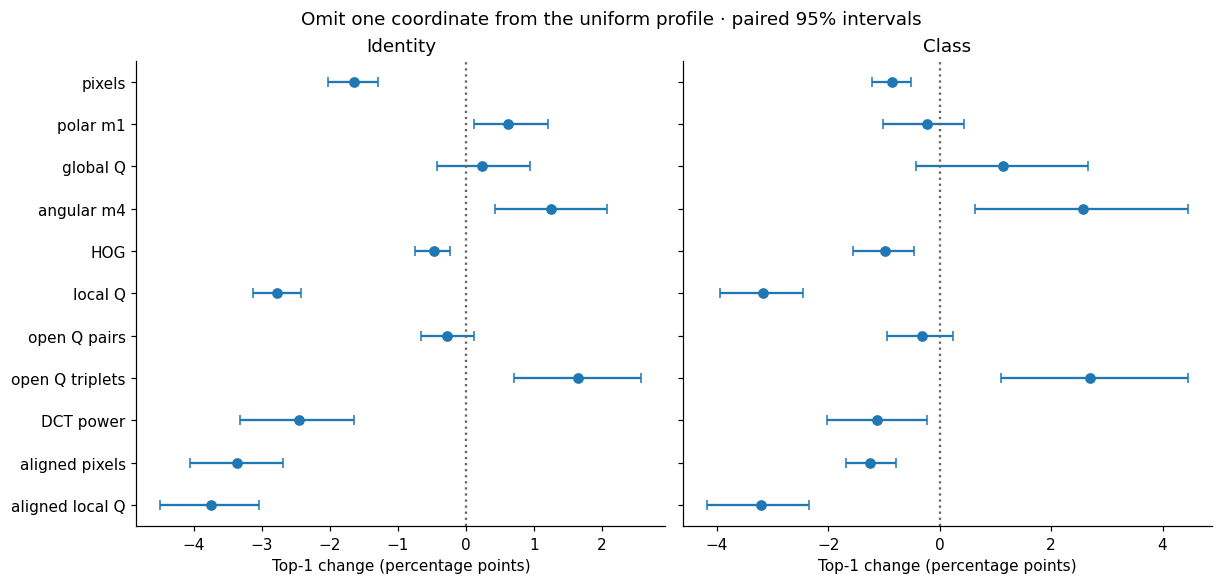

In [3]:
ablation=pd.read_csv(OUT/'uniform_ablation.csv') if (OUT/'uniform_ablation.csv').exists() else run(SOURCE,OUT)['uniform_ablation']
baseline=pd.read_csv(SOURCE/'transformed_summary.csv').set_index('method')
for endpoint in ['identity','class']:
    expected=baseline.loc['uniform profile',endpoint]
    actual=ablation.query("endpoint==@endpoint and variant=='full uniform'").top1.item()
    np.testing.assert_allclose(actual,expected,atol=1e-12)
display(ablation.sort_values(['endpoint','change'],ascending=[True,False]).round(4))
fig,axes=plt.subplots(1,2,figsize=(11,5.2),sharey=True)
order=['omit '+j for j in COMPONENTS]
for i,(ax,endpoint) in enumerate(zip(axes,['identity','class'])):
    z=ablation[ablation.endpoint==endpoint].set_index('variant').loc[order]
    ax.errorbar(z.change*100,np.arange(len(order)),
                xerr=np.maximum(0.,np.stack([z.change-z.low95,z.high95-z.change])*100),
                fmt='o',capsize=3)
    ax.axvline(0,ls=':',color='.4')
    ax.set(yticks=np.arange(len(order)),title=endpoint.capitalize(),xlabel='Top-1 change (percentage points)')
axes[0].set_yticklabels(COMPONENTS);axes[0].invert_yaxis()
fig.suptitle('Omit one coordinate from the uniform profile · paired 95% intervals')
show('27_uniform_ablation')

## Read ablation together with the intervention audit
Open Q triplets can detect the exact synthetic collisions established earlier. On this finite-digit gallery, they also respond to noise and rotation. In the equal-weight combination, removing triplets improves both endpoints. That is a consequence of this decision and task, not a test of whether all third-order information is redundant.

These omissions were examined on the test panel. Their intervals are marginal and unadjusted for the eleven omissions. Treat the results as hypotheses for a separate development study. The audit neither fits replacement weights nor uses test outcomes to select a new deployed profile.